In [1]:
# Libraries:
import numpy as np
import matplotlib.pyplot as plt
import dill
import sys
import os

import pysindy as ps
import D_CODE

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..'))) # include parent directory in the path
from data import SINDy_data
from data import data
from data import equations

from toolbox.auxiliary_functions import SRT_simulation, D_CODE_simulation, set_param_freq

# Seed:
np.random.seed(999)

/home/mattg/miniforge3/envs/SimbSINDy_env/lib/python3.11/site-packages/pysindy/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound


#### Case $\mu$, $A$ and $\omega$ fixed
Consider the modified Van der Pol system with a nonlinear forcing term
$$
\begin{cases}
\dot{x}_0 = \mu x_0 - x_1 - \mu x_0 x_1^2 + A\sin(\omega x_1^2) \\
\dot{x}_1 = x_0
\end{cases}
$$
and with $\mu=1$, $A=1$ and $\omega=1$ fixed.

In [2]:
# Select ODE & settings:
ode_name = 'OscilVdpODE' # help="name of the ode", type=str
ode_param = None # '1.,1.,1.' # help="parameters of the ode (default: None)", type=str, default=None
freq = 10 # help="sampling frequency", type=float, default=10
n_sample = 50 # help="number of trajectories", type=int, default=100
noise_ratio = 0.01 # help="noise level (default 0)", type=float, default=0.
seed = 103 # help="random seed", type=int, default=0
n_seed = 1 # help="random seed", type=int, default=10

ode_param, freq = set_param_freq(ode_param, freq)

ode = equations.get_ode(ode_name, ode_param)
dt = 1 / freq
dim_x = 2
dim_k = 0
time_vector = np.arange(0, ode.T + dt, dt)
T = ode.T

#### SR-T run

> **Remark.** Before running the experiments, make sure that the following settings are correctly configured in the `D_CODE` library:
>
> * In `config.py`, set:
>
>   ```python
>   n_generations = 20
>   functions_set = {'neg': 1, 'mul': 1, 'add': 1, 'sub': 1, 'pow': 1, 'sin': 1, 'cos': 1}
>   parsimony_coefficient = 0.01 
>   ```
> * In `gp_utils.py`, uncomment the line of code responsible for extracting the Oscillating Van der Pol ODE .

In [3]:
# running SR-T:
building_blocks_lambda0, function_names0 = SRT_simulation(ode_name, ode_param, 0, freq, n_sample, noise_ratio, alg='tv', seed=seed, n_seed=n_seed, T=T)
building_blocks_lambda1, function_names1 = SRT_simulation(ode_name, ode_param, 1, freq, n_sample, noise_ratio, alg='tv', seed=seed, n_seed=n_seed, T=T)

Running with: ode_name=OscilVdpODE, ode_param=None, x_id=0, freq=10, n_sample=50, noise_sigma=0.01, alg=tv, seed=103, n_seed=1
Dataset shape:  (101, 50, 2)
Functions set:  {'neg': 1, 'mul': 1, 'add': 1, 'sub': 1, 'pow': 1, 'sin': 1, 'cos': 1}
 
    |   Population Average    |             Best Individual              |
---- ------------------------- ------------------------------------------ ----------
 Gen   Length          Fitness   Length          Fitness      OOB Fitness  Time Left
   0     9.03       4.0901e+07        9           0.7238         0.656697      4.85m


/home/mattg/gplearn/gplearn/functions.py:132: RuntimeWarning: overflow encountered in power
  return np.where(np.logical_and(np.minimum(x1, x2) >= 0, np.maximum(x1, x2) <= 10), np.power(x1, x2), 1000)
/home/mattg/gplearn/gplearn/functions.py:132: RuntimeWarning: overflow encountered in power
  return np.where(np.logical_and(np.minimum(x1, x2) >= 0, np.maximum(x1, x2) <= 10), np.power(x1, x2), 1000)


   1     4.60           316.73        9         0.716019          0.72672      4.11m
   2     4.85          72.5427       10         0.665144         0.598558      3.74m
   3     5.91          15983.2       11         0.592381         0.632758      5.09m
   4     6.34          9806.75       11         0.589751         0.656432      6.61m
   5     6.57          9955.67       13         0.458175         0.495218      6.65m
   6     6.71          96.2385       14         0.431276         0.426834      5.20m
   7     7.93          256.314       14         0.394269         0.406683      3.95m
   8     9.85          324.154       14         0.369858          0.39438      6.57m
   9    10.66          127.124       15         0.273418         0.261329      3.88m
  10    11.27          54.5198       13         0.264202         0.234347      2.86m
  11    12.42          9998.12       17         0.203912         0.217667      3.26m
  12    13.24          194.903       14         0.102693         

##### Plot per report

In [4]:
from report import evaluate_traj, SRModel

# Define the Symbolic Regression model cohirently with the SINDy model
f = lambda x, t: [x[0]*(0.9999316180527035 - x[1]**2) - x[1] + np.sin(x[1]**2), 
                  x[0]]
model = SRModel(f)


In [9]:
# Evaluate RSME on 10 test trajectories
n_test = 10
rmse, _ = SINDy_data.evaluate_RMSE(model, ode, freq, n_test, [1., 1.], [0., 0.], dim_k)
print('SR-T Model RMSE: ', rmse)

SR-T Model RMSE:  0.00718860626453847


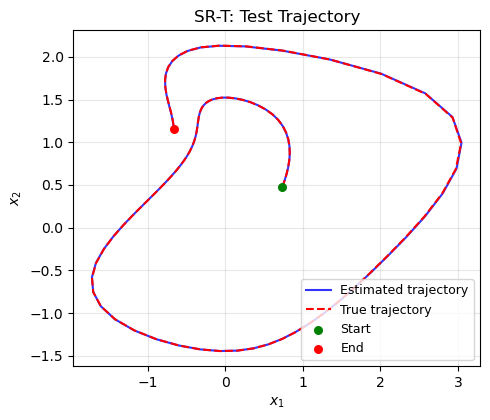

In [6]:
# Simulate a test trajectory starting from an initial condition within the training interval
evaluate_sample = 1
ics = [0.7, 0.4]
title = 'SR-T: Test Trajectory'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=10)

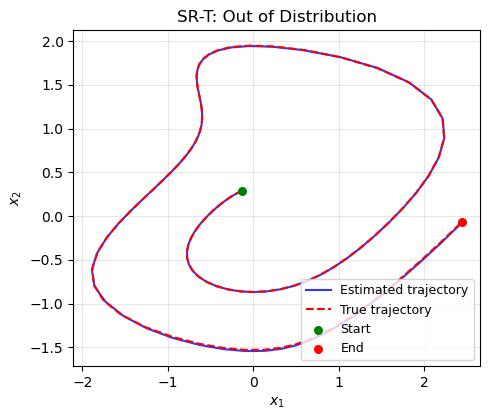

In [7]:
# Simulate a test trajectory starting from an initial condition outside the training interval
evaluate_sample = 1
ics = [-0.1, 0.3]
title = 'SR-T: Out of Distribution'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=10)

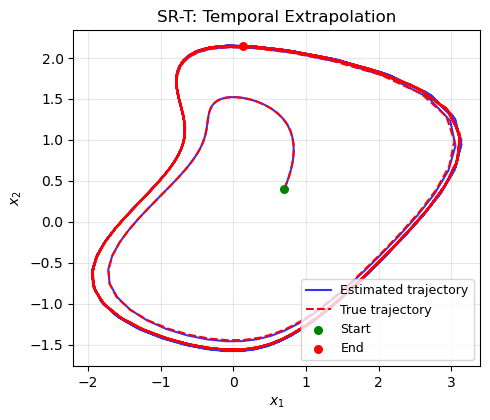

In [8]:
# Simulate a test trajectory starting from an initial condition within the training interval 
# but with focus on a longer extrapolation time
evaluate_sample = 1
ics = [0.7, 0.4]
title = 'SR-T: Temporal Extrapolation'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=40)

#### D-CODE run

> **Remark.** Before running the experiments, make sure that the following settings are correctly configured in the `D_CODE` library:
>
> * In `config.py`, set:
>
>   ```python
>   n_generations = 20
>   functions_set = {'neg': 1, 'mul': 1, 'add': 1, 'sub': 1, 'pow': 1, 'sin': 1, 'cos': 1}
>   parsimony_coefficient = 2.0 
>   ```
> * In `gp_utils.py`, uncomment the line of code responsible for extracting the Oscillating Van der Pol ODE .

In [3]:
# running D-CODE
building_blocks_lambda0, function_names0 = D_CODE_simulation(ode_name, ode_param, 0, freq, n_sample, noise_ratio, seed=seed, n_seed=n_seed, T=T)
building_blocks_lambda1, function_names1 = D_CODE_simulation(ode_name, ode_param, 1, freq, n_sample, noise_ratio, seed=seed, n_seed=n_seed, T=T)

Running with: ode_name=OscilVdpODE, ode_param=None, x_id=0, freq=10, n_sample=50, noise_sigma=0.01, seed=103, n_seed=1
Dataset shape:  (201, 50, 2)
Functions set:  {'neg': 1, 'mul': 1, 'add': 1, 'sub': 1, 'pow': 1, 'sin': 1, 'cos': 1}
 
    |   Population Average    |             Best Individual              |
---- ------------------------- ------------------------------------------ ----------
 Gen   Length          Fitness   Length          Fitness      OOB Fitness  Time Left
   0     9.03      9.23078e+21        9          124.183          123.216      4.00m
   1     5.11      1.95279e+11        6            118.2          116.958      3.55m
   2     3.28       1.6673e+10       11          102.383           117.88      2.92m
 
promising programs:
add(sub(mul(neg(sub(cos(4.388), neg(X1))), X0), X1), sin(pow(X1, 1.820)))
sub(mul(sub(cos(sub(cos(X1), X1)), X1), X0), X1)
sub(mul(cos(pow(X1, 1.648)), X0), X1)
sub(mul(cos(pow(X1, 1.648)), X0), X1)
add(sin(pow(X1, 1.829)), sub(neg(X1), mul(

##### Plot per report

In [ ]:
from report import evaluate_traj, SRModel

# Define the Symbolic Regression model
f = lambda x, t: [ x[0]*np.cos(1.7301545306005086*x[1]) - x[1] + np.sin(x[1]**2),
                   x[0] ]

model = SRModel(f)

In [6]:
# Evaluate RSME on 10 test trajectories
n_test = 10
rmse, _ = SINDy_data.evaluate_RMSE(model, ode, freq, n_test, [1., 1.], [0., 0.], dim_k)
print('D-CODE Model RMSE: ', rmse)

D-CODE Model RMSE:  0.27693719187340093


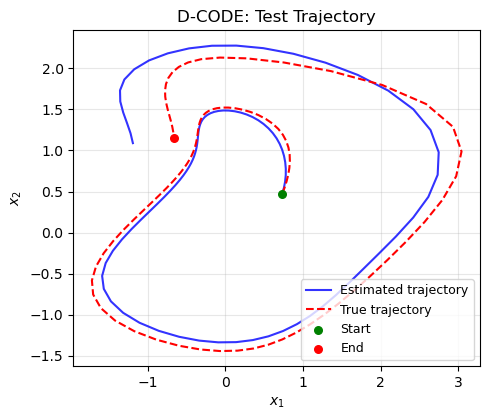

In [7]:
# Simulate a test trajectory starting from an initial condition within the training interval
evaluate_sample = 1
ics = [0.7, 0.4]
title = 'D-CODE: Test Trajectory'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=10)

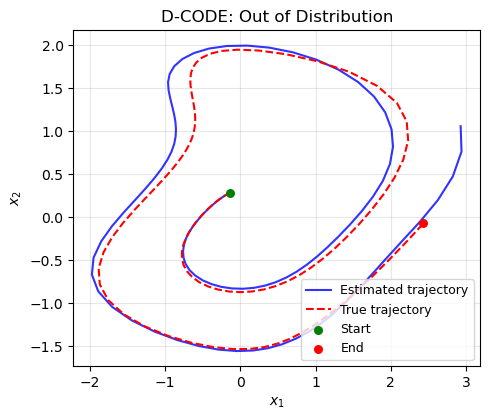

In [8]:
# Simulate a test trajectory starting from an initial condition outside the training interval
evaluate_sample = 1
ics = [-0.1, 0.3]
title = 'D-CODE: Out of Distribution'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=10)

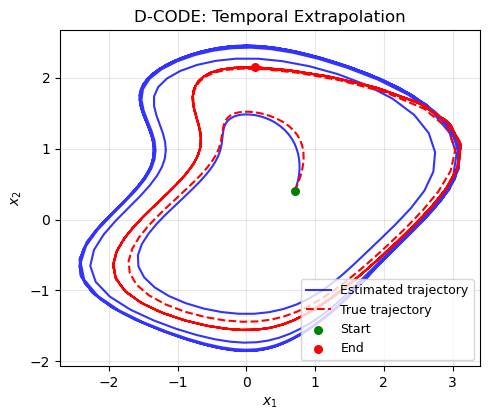

In [9]:
# Simulate a test trajectory starting from an initial condition within the training interval 
# but with focus on a longer extrapolation time
evaluate_sample = 1
ics = [0.7, 0.4]
title = 'D-CODE: Temporal Extrapolation'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=40)